# KMeans - Code

Dans ce bloc de code :

1. On importe **pandas**, pour manipuler facilement des tableaux de données.
2. On importe **Plotly**, une librairie pour créer des graphiques interactifs (`plotly.express` pour les graphiques rapides, `plotly.graph_objects` pour les graphiques plus personnalisés).
3. On crée une **palette de couleurs personnalisée** nommée “Jedha” pour uniformiser les couleurs des graphiques.
4. On définit cette palette comme **défaut** pour tous les graphiques.
5. On définit le **mode de rendu** des graphiques (`svg` ici, ou `iframe` selon l’environnement).

Ce code prépare l’environnement pour **analyser et visualiser les données de manière esthétique et cohérente**.


In [ ]:
import pandas as pd

# Import plotly
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# setting Jedha color palette as default
pio.templates["jedha"] = go.layout.Template(
    layout_colorway=["#4B9AC7", "#4BE8E0", "#9DD4F3", "#97FBF6", "#2A7FAF", "#23B1AB", "#0E3449", "#015955"]
)
pio.templates.default = "jedha"
pio.renderers.default = "svg" # to be replaced by "iframe" if working on JULIE

## Dataset 🔥🔥

Dans cet exemple, nous allons utiliser le **dataset Iris** de **Scikit-Learn**, très utilisé pour les démonstrations de clustering.

* On importe la fonction `load_iris` depuis `sklearn.datasets`.
* On charge les **caractéristiques** des fleurs dans un **DataFrame** appelé `X`.

  * On n’utilise pas la variable cible (`y`), car le clustering est une **apprentissage non supervisé**.
* On affiche les **5 premières lignes** avec `X.head()` pour avoir un aperçu des données.

En résumé, ce code prépare le **jeu de données** que nous allons analyser avec K-Means.

In [2]:
# Importer le jeu de données Iris depuis scikit-learn
from sklearn.datasets import load_iris

# Charger les données Iris dans un DataFrame
# Ici, on récupère uniquement les caractéristiques (features) et on ignore la variable cible
# On utilise "_" pour indiquer que cette valeur n'est pas utilisée
X, _ = load_iris(return_X_y=True, as_frame=True)

# Afficher les 5 premières lignes pour avoir un aperçu des données
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## Normalize dataset 📏📏

Avant d’appliquer **K-Means**, il est important de **normaliser les données**.

* Pourquoi ? K-Means utilise la **distance Euclidienne**, donc si certaines variables ont des valeurs beaucoup plus grandes que d’autres, elles **influeront trop sur le clustering**.
* On utilise `StandardScaler` de **scikit-learn** :

  * Il **soustrait la moyenne** et **divise par l’écart-type** pour chaque variable.
* On applique cette transformation au dataset `X`.
* Après normalisation, `X` devient un **array NumPy**, donc pour visualiser, on affiche les **5 premières lignes avec `X[:5]`**.

Cette étape assure que **toutes les variables ont la même importance** pour K-Means.

In [ ]:
# Importer StandardScaler depuis scikit-learn
from sklearn.preprocessing import StandardScaler

# Initialiser le StandardScaler
# StandardScaler soustrait la moyenne et divise par l'écart-type pour chaque observation
sc = StandardScaler()

# Appliquer le StandardScaler aux données
X = sc.fit_transform(X)

# Afficher les 5 premières lignes transformées
# Après transformation, X devient un tableau numpy, donc on ne peut plus utiliser .head()
X[:5]

array([[-0.90068117,  1.01900435, -1.34022653, -1.3154443 ],
       [-1.14301691, -0.13197948, -1.34022653, -1.3154443 ],
       [-1.38535265,  0.32841405, -1.39706395, -1.3154443 ],
       [-1.50652052,  0.09821729, -1.2833891 , -1.3154443 ],
       [-1.02184904,  1.24920112, -1.34022653, -1.3154443 ]])

## Apply K-Means 🚀🚀

Nous allons maintenant **appliquer K-Means** sur le dataset Iris.

* On sait que le dataset contient **3 types de fleurs**, donc on initialise **K = 3**.

  * Nous verrons plus tard comment confirmer que ce nombre est optimal.
* On utilise `KMeans` de scikit-learn :

  * `n_clusters=3` → nombre de clusters
  * `random_state=0` → pour reproduire les résultats
  * `k-means++` → initialisation qui **évite les problèmes de minimum local**
* Ensuite, on **entraîne l’algorithme** avec `kmeans.fit(X)` sur les données normalisées.

Cette étape **regroupe automatiquement les fleurs en 3 clusters** en fonction de leurs caractéristiques.


In [4]:
# Importer l'algorithme K-Means depuis scikit-learn
from sklearn.cluster import KMeans

# L'algorithme commence par choisir des centres de départ pour les clusters.
# Par défaut, scikit-learn utilise "k-means++" : les centres sont choisis intelligemment pour que l'algorithme ne se trompe pas au début.
kmeans = KMeans(n_clusters=3, random_state=0)

# n_clusters=3 : on souhaite identifier 3 groupes dans les données (ici, correspondant aux 3 espèces d’Iris).
# random_state=0 : permet d’avoir les mêmes résultats à chaque exécution, ce qui est utile pour la reproductibilité.

# Appliquer K-Means sur notre jeu de données
kmeans.fit(X)




,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


Notre modèle K-Means est maintenant **initialisé et convergé**. Il est temps d’examiner les **coordonnées des centres des clusters** :

* `kmeans.cluster_centers_` contient les **centres des clusters** sur les données **normalisées**.
* Pour obtenir les valeurs réelles des caractéristiques, on utilise `sc.inverse_transform`.
* On crée un **DataFrame** avec les noms des colonnes pour mieux visualiser les centres.
* Enfin, on utilise Plotly (`ff.create_annotated_heatmap`) pour créer une **heatmap annotée**, montrant les valeurs de chaque centre de cluster pour chaque caractéristique.

Attention : pour exporter un graphique Plotly en image, il faut installer plotly et le package **kaleido** avec `pip install -U plotly kaleido` et redémarrer, sinon une erreur apparaîtra.

Cette visualisation permet de **comprendre rapidement les caractéristiques moyennes de chaque cluster**.


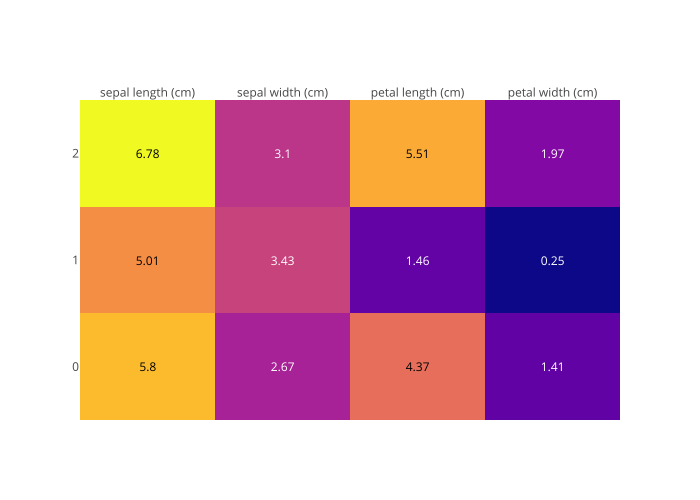

In [5]:
# Coordonnées des centres de clusters
# On applique la transformation inverse du StandardScaler pour retrouver les valeurs originales
cluster_centers = sc.inverse_transform(kmeans.cluster_centers_)

# Récupérer les noms des colonnes pour faciliter la compréhension
labels = load_iris().feature_names

# Construire un DataFrame avec les centres de clusters et arrondir les valeurs à 2 décimales
matrix = pd.DataFrame(cluster_centers, columns=labels).round(2)

# Créer la heatmap avec Plotly

import plotly.figure_factory as ff

fig = ff.create_annotated_heatmap( # `figure_factory.create_annotated_heatmap` permet d'afficher les valeurs directement dans chaque cellule
    z=matrix.values,             # Les données numériques à afficher dans la heatmap
    x=matrix.columns.tolist(),   # Noms des colonnes (axes X)
    y=matrix.index.tolist()      # Index des lignes (axes Y), ici les clusters
)

# Afficher la figure interactive
fig.show()


Pour savoir **dans quel cluster une nouvelle observation sera classée**, on peut utiliser la méthode `.predict()` de K-Means :

1. On crée une **nouvelle observation** avec NumPy (`d`).
2. On **normalise** cette observation avec le même `StandardScaler` utilisé pour le dataset (`sc.transform(d)`).
3. On applique `kmeans.predict(d)` pour obtenir le **cluster auquel elle appartient**.
4. On affiche le résultat avec `print`.

`.predict()` permet de **classer rapidement de nouvelles données** selon les clusters déjà appris par K-Means.


In [11]:
# Créer une nouvelle observation avec numpy
import numpy as np
d = np.array([ [6, 2, 1, 8]])   # Chaque valeur correspond à une caractéristique de l'Iris que nous inventons

# Appliquer le même StandardScaler que pour les données d'entraînement
# Cela met la nouvelle observation sur la même échelle que les clusters
d = sc.transform(d)

# Prédire à quel cluster appartient cette nouvelle observation
c = kmeans.predict(d)

# Afficher le résultat
print(f"Cette observation appartient au cluster : {c[0]}")


Cette observation appartient au cluster : 2


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Cet observation serait donc dans la class 2 selon K-Means.

Le message :

```

UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
```

n’est **pas une erreur**, c’est un **avertissement**.

* Il apparaît parce que le `StandardScaler` a été entraîné sur un **DataFrame avec noms de colonnes**, mais la nouvelle observation `d` est un **array NumPy sans noms**.
* Le scaler peut quand même transformer les données, l’avertissement sert simplement à **prévenir du manque de noms de colonnes**.

L’avertissement signifie juste que la nouvelle donnée n’a pas de noms de colonnes, mais le modèle peut quand même la classer correctement.



## Select $K$ optimal clusters

### Elbow method 💪

Pour savoir **combien de clusters choisir**, on peut utiliser la **méthode du Coude (Elbow Method)**.

* On teste différents nombres de clusters (ici de 1 à 10).
* Pour chaque valeur de K :

  1. On entraîne un K-Means sur les données normalisées.
  2. On récupère le **Within-Cluster Sum of Squares (WCSS)** avec `.inertia_` → mesure de la **dispersion des points dans les clusters**.
  3. On stocke les valeurs pour pouvoir les **visualiser ensuite**.
* Le but : repérer **l’endroit où l’amélioration de WCSS commence à ralentir**, appelé le “coude”, qui indique le **nombre optimal de clusters**.

In [ ]:
# On va créer une boucle pour calculer le "Within-Cluster Sum of Squares" (WCSS) pour différentes valeurs de K
# WCSS mesure la somme des distances au carré entre chaque point et le centre de son cluster.
# Plus WCSS est faible, plus les points sont proches de leur centre.

wcss = []  # Liste pour stocker les valeurs de WCSS
k = []     # Liste pour stocker les valeurs de K testées

for i in range(1, 11):
    # Créer un K-Means avec i clusters
    # n_init='auto' indique combien de fois l'algorithme est relancé pour trouver une meilleure solution
    kmeans = KMeans(n_clusters=i, random_state=0, n_init='auto')
    
    # Appliquer K-Means sur les données
    kmeans.fit(X)
    
    # Récupérer la WCSS et l'ajouter à la liste
    wcss.append(kmeans.inertia_)
    k.append(i)
    
    # Afficher la WCSS pour ce nombre de clusters
    # i : c’est le nombre de clusters que tu es en train de tester dans la boucle.
    # wcss[-1] : c’est la dernière valeur ajoutée à la liste wcss, donc la WCSS correspondante à ce nombre de clusters.
    print("WCSS pour K={} --> {}".format(i, wcss[-1]))






WCSS pour K=1 --> 600.0
WCSS pour K=2 --> 222.361704965023
WCSS pour K=3 --> 139.8204963597497
WCSS pour K=4 --> 114.09254690403083
WCSS pour K=5 --> 90.80759161913355
WCSS pour K=6 --> 81.50473906581254
WCSS pour K=7 --> 72.82103962425717
WCSS pour K=8 --> 65.2445359401414
WCSS pour K=9 --> 57.30734937433054
WCSS pour K=10 --> 47.26371568868683


Observons le résultat avec une visualisation.

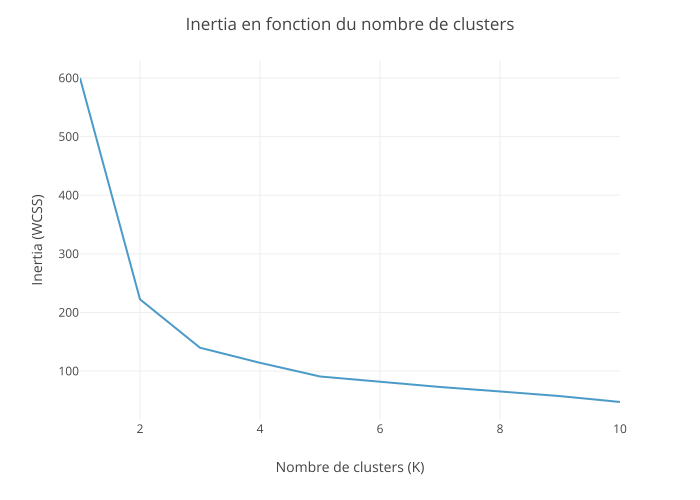

In [ ]:
# Créer un DataFrame à partir des valeurs de WCSS
wcss_frame = pd.DataFrame(wcss)

# Créer une Series pour les valeurs de K testées
k_frame = pd.Series(k)

# Créer la figure avec plotly express
# On trace WCSS (inertia) en fonction du nombre de clusters
import plotly.express as px
fig = px.line(
    wcss_frame,            # Les valeurs de WCSS
    x=k_frame,             # Axe X : nombre de clusters
    y=wcss_frame.iloc[:, -1]  # Axe Y : WCSS correspondant
)

# Ajouter un titre et des noms aux axes
fig.update_layout(
    yaxis_title="Inertia (WCSS)",  # Axe Y : somme des distances au carré
    xaxis_title="Nombre de clusters (K)",  # Axe X : nombre de clusters testés
    title="Inertia en fonction du nombre de clusters"  # Titre du graphique
)

# Afficher la figure
# fig.show(renderer="notebook")  # à utiliser dans certains notebooks
fig.show() 


On cherche à observer le point à partir duquel la **WCSS** n’augmente plus beaucoup.

* Cela signifie que **rajouter plus de clusters n’améliore pas beaucoup la dispersion** des points dans les clusters.

## Silhouette 👥

Pour **confirmer le nombre optimal de clusters**, on peut utiliser la **méthode Silhouette** :

* Elle mesure **la qualité de séparation des clusters** : un score élevé signifie que les points sont **bien regroupés dans leur cluster et éloignés des autres clusters**.
* On calcule le score pour différents nombres de clusters (ici de **2 à 10** car le score nécessite au moins 2 clusters).
* Pour chaque K :

  1. On entraîne un K-Means sur les données normalisées.
  2. On prédit les clusters pour les points.
  3. On calcule le **Silhouette Score** avec `silhouette_score`.
* L’objectif : trouver **le K qui maximise le score**, confirmant ainsi le nombre optimal de clusters.

In [15]:
# Importer la fonction silhouette_score depuis scikit-learn
from sklearn.metrics import silhouette_score

# Listes pour stocker les scores et les valeurs de K testées
sil = []  # Silhouette score
k = []    # Nombre de clusters

# Attention : on commence à i=2 car le silhouette score nécessite au moins 2 clusters
for i in range(2, 11):
    # Créer un K-Means avec i clusters
    kmeans = KMeans(n_clusters=i, random_state=0, n_init='auto')
    
    # Appliquer K-Means sur les données
    kmeans.fit(X)
    
    # Calculer le score de silhouette pour ce clustering
    # Le score mesure à quel point les points sont bien regroupés dans leur cluster
    sil.append(silhouette_score(X, kmeans.predict(X)))
    
    # Stocker le nombre de clusters
    k.append(i)
    
    # Afficher le score pour ce nombre de clusters
    print("Silhouette score pour K={} --> {}".format(i, sil[-1]))


Silhouette score pour K=2 --> 0.5817500491982808
Silhouette score pour K=3 --> 0.45994823920518646
Silhouette score pour K=4 --> 0.38694104154427816
Silhouette score pour K=5 --> 0.3455109959980946
Silhouette score pour K=6 --> 0.3437191888640957
Silhouette score pour K=7 --> 0.3292362209841344
Silhouette score pour K=8 --> 0.3351935187631491
Silhouette score pour K=9 --> 0.3524877506768797
Silhouette score pour K=10 --> 0.34860741568769404


Nous allons maintenant **visualiser les scores Silhouette et WCSS** avec **Plotly** :

* L’objectif est de **comparer facilement les différents nombres de clusters**.
* Grâce à la visualisation, on peut repérer **rapidement le nombre optimal de clusters** :

  * Pour WCSS → le “coude”
  * Pour Silhouette → le **score maximum**

Cette étape permet de **prendre une décision éclairée** sur le nombre de clusters à utiliser pour K-Means.

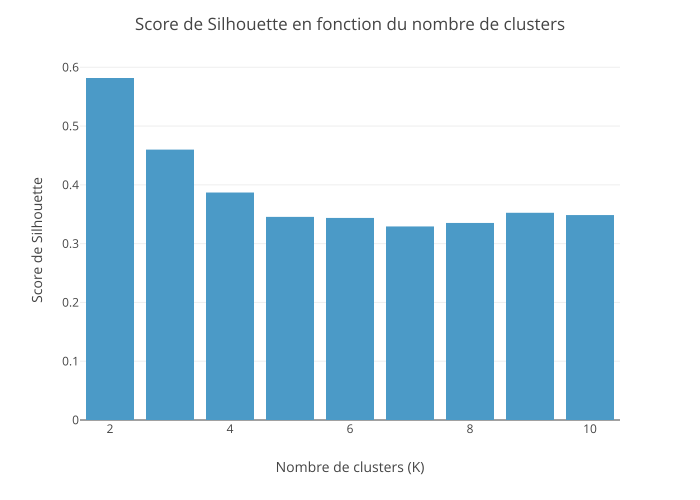

In [16]:
# Créer un DataFrame à partir des scores de silhouette
cluster_scores = pd.DataFrame(sil)

# Créer une Series pour les valeurs de K testées
k_frame = pd.Series(k)

# Créer un graphique en barres avec plotly express
# On trace le score de silhouette en fonction du nombre de clusters
import plotly.express as px
fig = px.bar(
    data_frame=cluster_scores,  # Données du graphique
    x=k,                        # Axe X : nombre de clusters
    y=cluster_scores.iloc[:, -1] # Axe Y : score de silhouette
)

# Ajouter un titre et des noms aux axes
fig.update_layout(
    yaxis_title="Score de Silhouette",        # Axe Y
    xaxis_title="Nombre de clusters (K)",    # Axe X
    title="Score de Silhouette en fonction du nombre de clusters"  # Titre du graphique
)

# Afficher le graphique
fig.show()  


La **méthode Silhouette** suggère cette fois de choisir **K = 2** clusters au lieu de 3.

* Cela montre pourquoi il est important d’utiliser **plusieurs méthodes** pour déterminer K.
* Au final, le choix dépend aussi **de votre connaissance métier et de votre intuition** sur les données.

## Resources 📚📚

* <a href="https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html?highlight=kmeans#sklearn.cluster.KMeans" target="_blank"> KMeans </a>

* <a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html?highlight=silhouette#sklearn.metrics.silhouette_score" target="_blank">Silhouette Score</a>

* <a href="https://plotly.com/python/plotly-express/" target="_blank"> Plotly Express </a>

* <a href="https://plotly.com/python/renderers/" target="_blank">Plotly Renderers</a>